# 02 · Exploratory data analysis (train split only)
Each figure answers one question. The test split is excluded so no decision is influenced by it.
Figures are produced by `python -m src.eda`.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().resolve().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, Markdown, display
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 200)
from src import config
from src.eda import FIGURE_QUESTIONS
from src.features import build_feature_table
df = build_feature_table(); train = df[df.split == 'train']

### How imbalanced is the target in train and test?

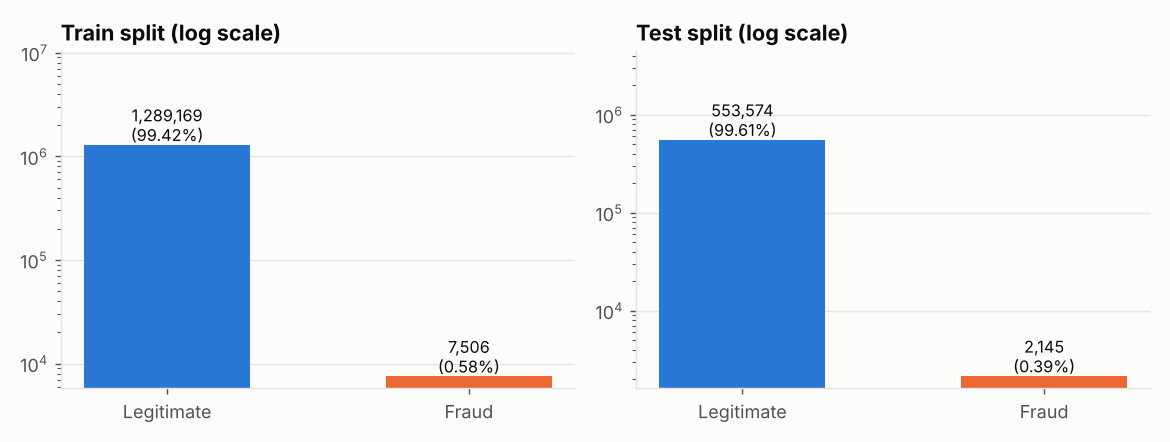

### How are transaction amounts distributed, and do fraud amounts differ from legitimate ones?

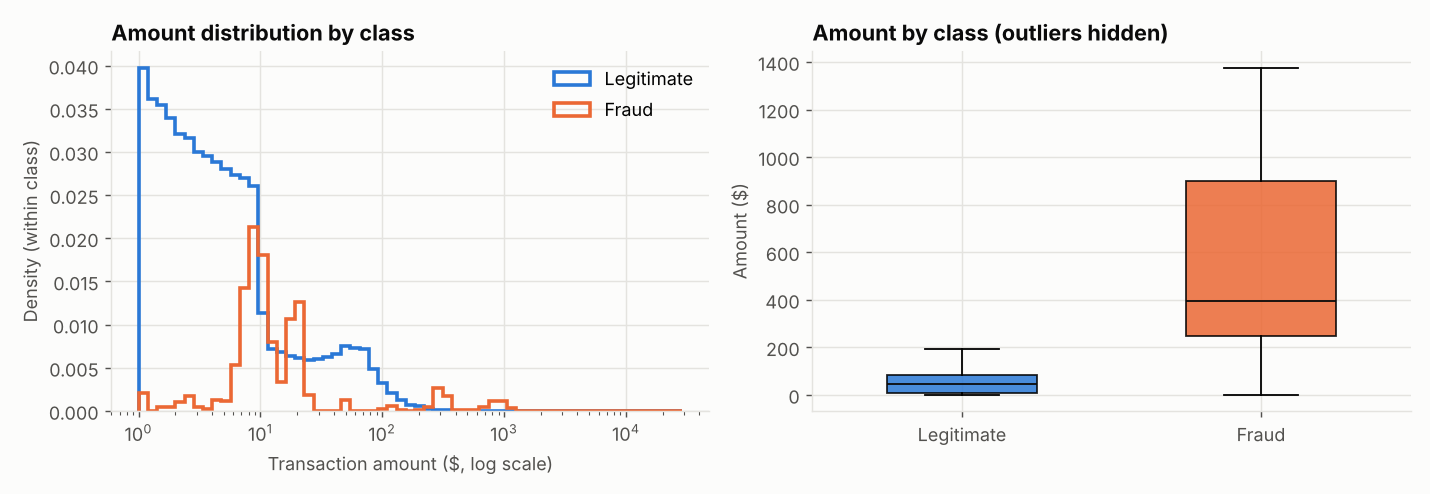

### Which merchant categories carry the highest fraud rate?

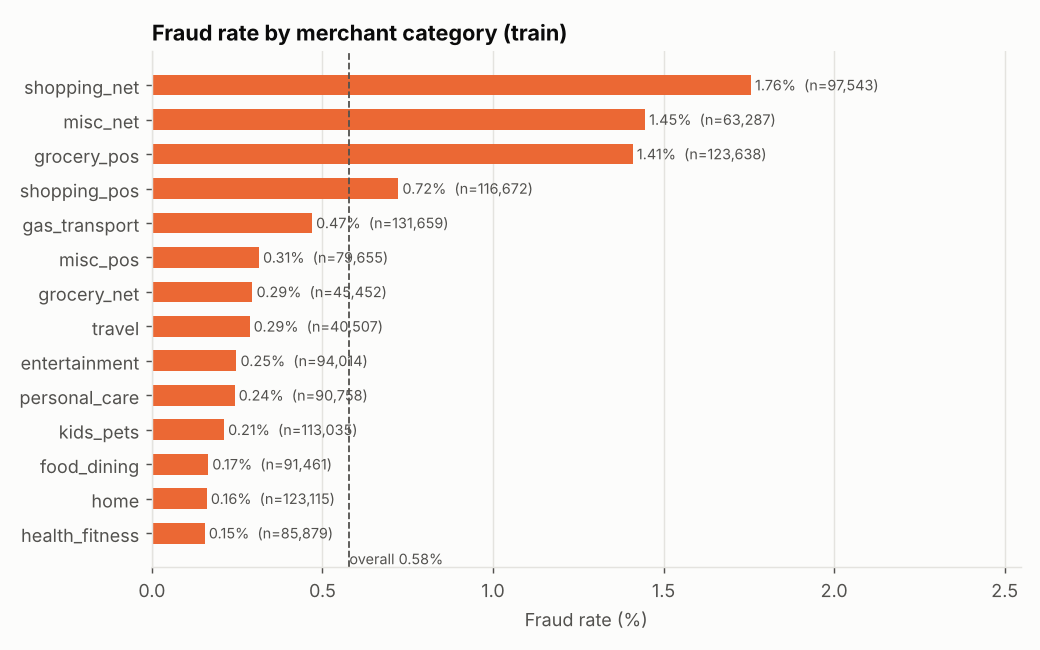

### Does fraud concentrate at particular hours or days?

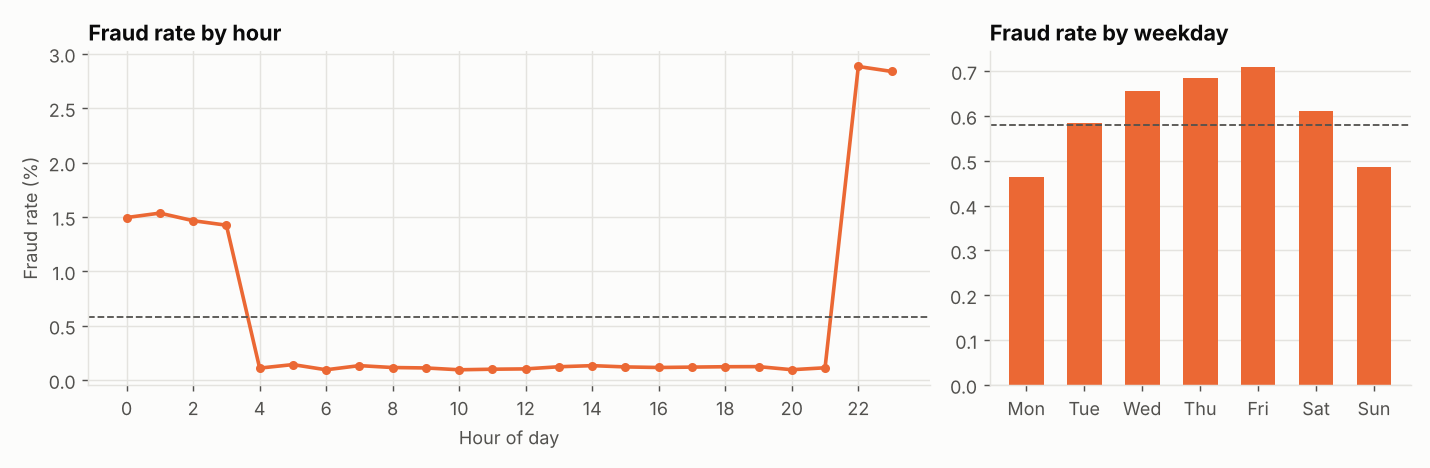

### Is state a reliable geographic signal, or just noise from few cards per state?

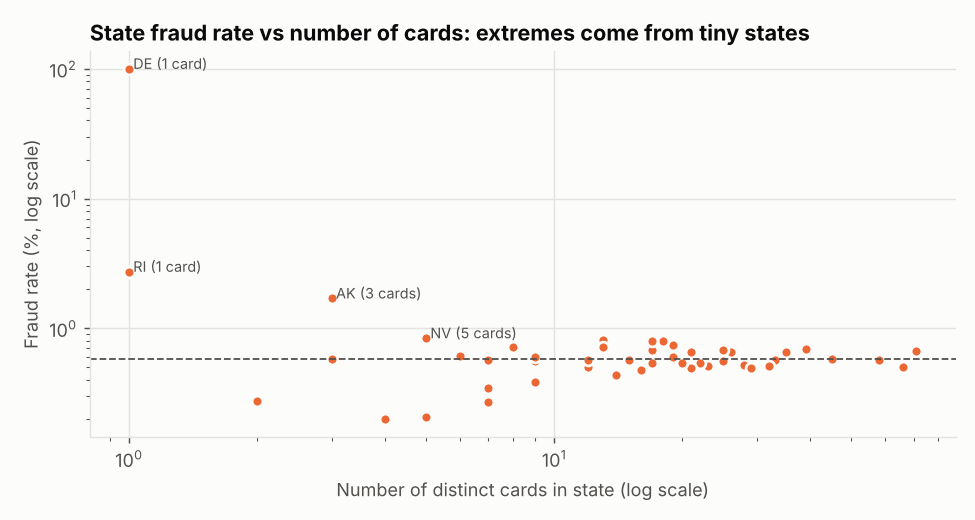

### Does fraud rate vary with cardholder age?

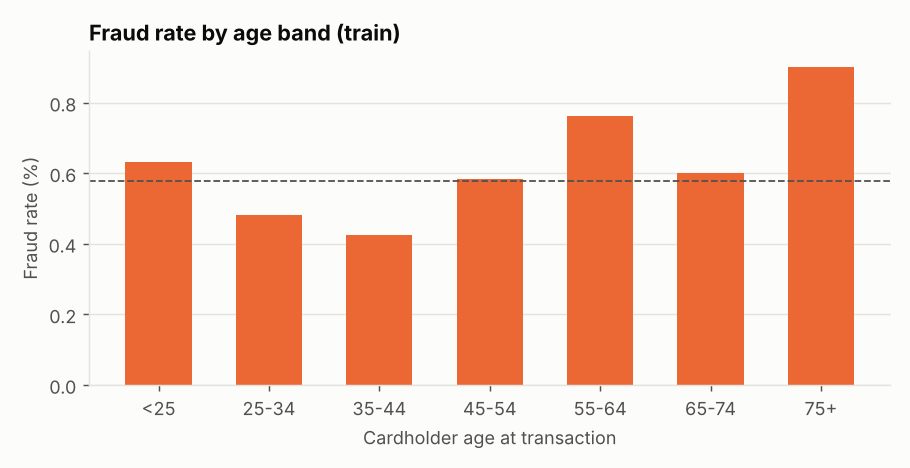

### Is transaction volume and fraud rate stable over time?

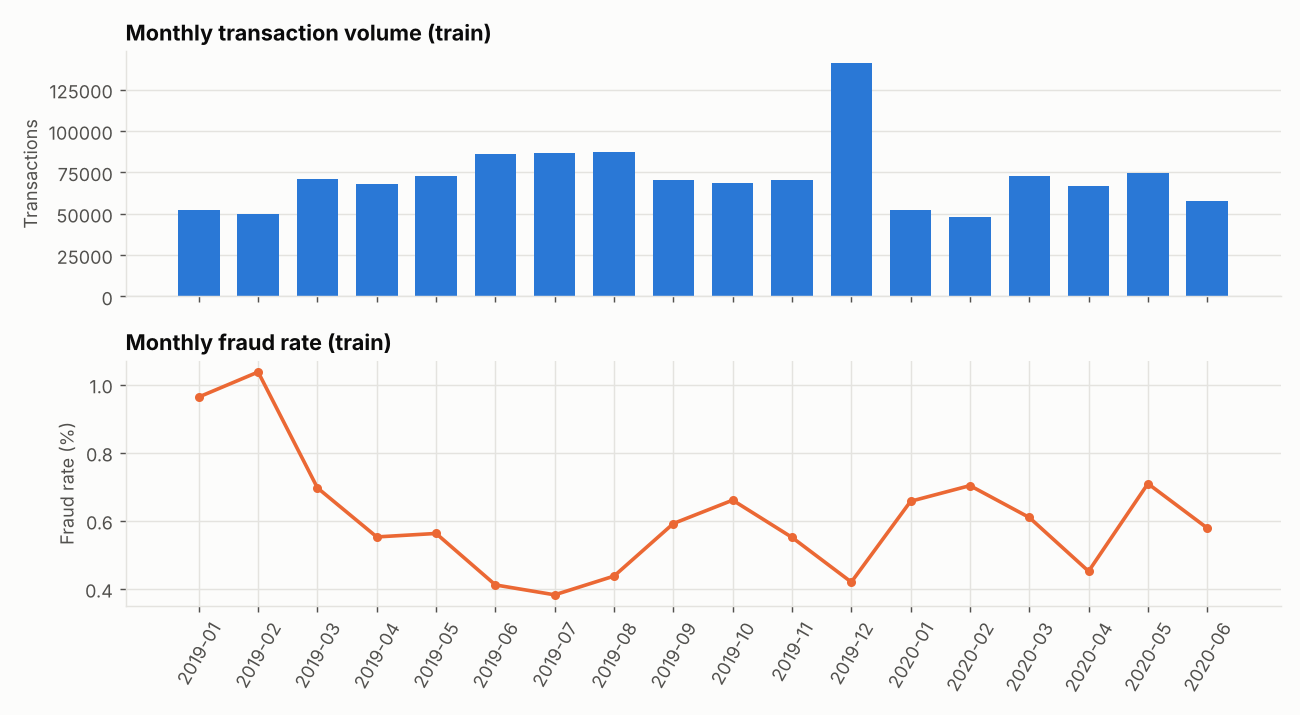

### Do the card-history features separate fraud from legitimate transactions?

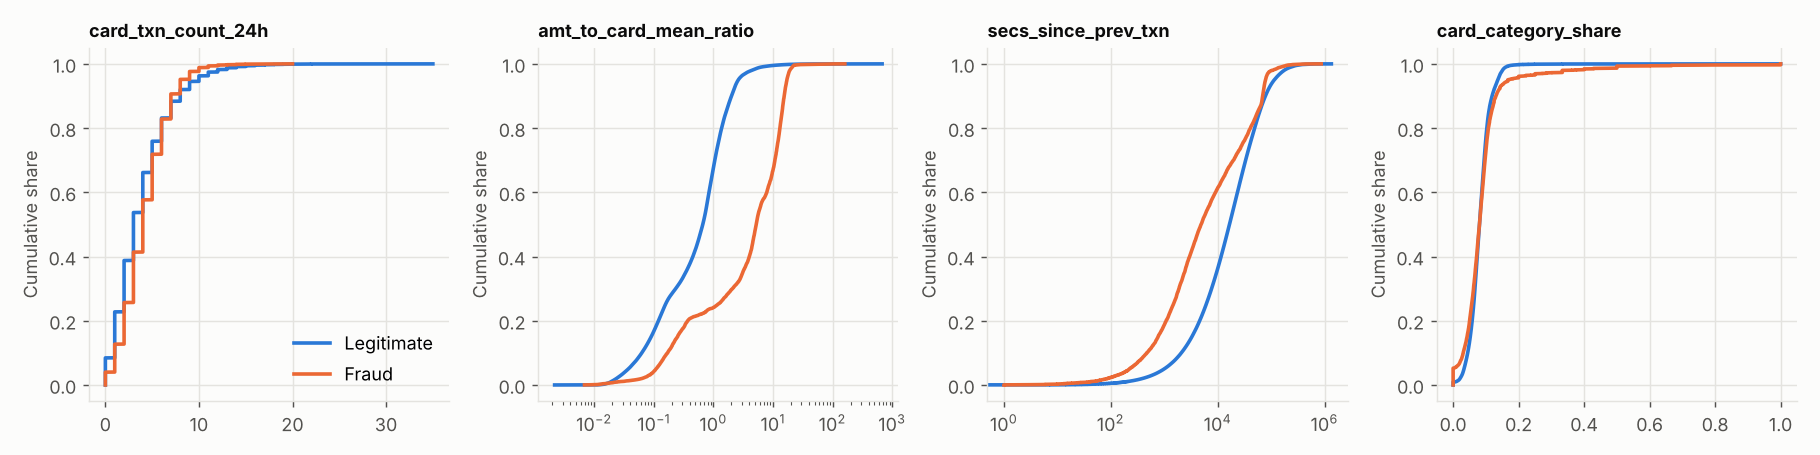

### How are the numeric inputs distributed for each class?

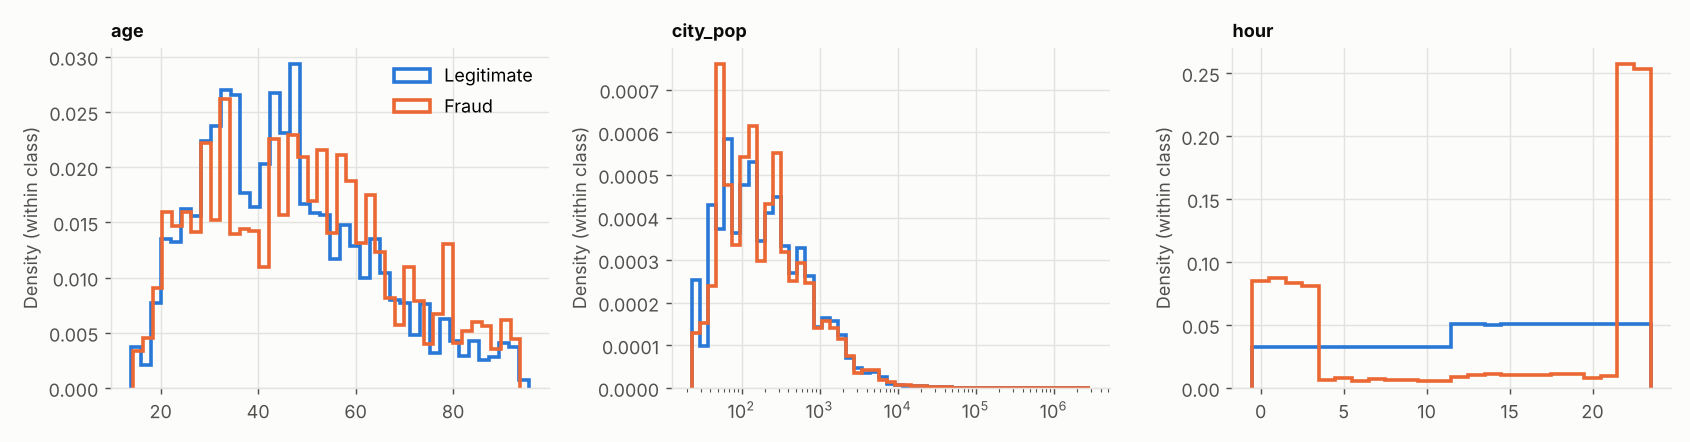

In [2]:
for fname, question in FIGURE_QUESTIONS.items():
    display(Markdown(f'### {question}'))
    display(Image(filename=str(config.FIGURES_DIR / fname)))

## Key numbers behind the figures

In [3]:
display(train.groupby(config.TARGET)['amt'].describe(percentiles=[.1,.25,.5,.75,.9]).round(2))
train.groupby('category')[config.TARGET].agg(['size','sum','mean']).sort_values('mean', ascending=False).round(4)

,count,mean,std,min,10%,25%,50%,75%,90%,max
is_fraud,,,,,,,,,,
0,1289169.0,67.67,154.01,1.00,4.09,9.61,47.28,82.54,134.21,28948.90
1,7506.0,531.32,390.56,1.06,11.98,245.66,396.50,900.88,1024.59,1376.04


,size,sum,mean
category,,,
shopping_net,97543,1713,0.0176
misc_net,63287,915,0.0145
grocery_pos,123638,1743,0.0141
shopping_pos,116672,843,0.0072
gas_transport,131659,618,0.0047
misc_pos,79655,250,0.0031
grocery_net,45452,134,0.0029
travel,40507,116,0.0029
entertainment,94014,233,0.0025


In [4]:
train.groupby('hour')[config.TARGET].mean().mul(100).round(3).to_frame('fraud_rate_pct').T

hour,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
fraud_rate_pct,1.494,1.535,1.465,1.424,0.11,0.142,0.095,0.133,0.115,0.111,0.095,0.1,0.103,0.122,0.133,0.121,0.116,0.119,0.123,0.124,0.095,0.113,2.883,2.837


Summary tables: `reports/eda_summary.md`.